In [1]:
def build_feature_map():
    feature_map = {}
    idx = 0

    # --------------------------------------------------
    # Mechanism type (11)
    # --------------------------------------------------
    for i in range(11):
        feature_map[idx] = f"mechanism_type={i}"
        idx += 1

    # --------------------------------------------------
    # Atom fingerprints (4 atoms × 35 bits)
    # --------------------------------------------------
    charge = ["charge=neg", "charge=pos"]
    hcount = ["H=0", "H=1", "H=2", "H>2"]
    hybrid = ["hybrid=sp", "hybrid=sp2", "hybrid=sp3"]
    elements = [
        "element=alkali",
        "element=B",
        "element=C",
        "element=N",
        "element=O",
        "element=F",
        "element=Mg",
        "element=Al",
        "element=Si",
        "element=P",
        "element=S",
        "element=Cl",
        "element=Br",
        "element=I",
        "element=transition_metal",
    ]
    aromatic = ["aromatic=no", "aromatic=yes"]
    adjacency = [
        "adj=C+",
        "adj=C-",
        "adj=CH",
        "adj=C-EN",
        "adj=C=EN",
        "adj=EN",
        "adj=EP",
        "adj=CH0",
        "adj=C(sp/sp2)",
    ]
    three_membered_ring = ["ring=3"]

    for atom_i in range(1, 5):
        prefix = f"atom{atom_i}"

        for label in charge:
            feature_map[idx] = f"{prefix}.{label}"
            idx += 1

        for label in hcount:
            feature_map[idx] = f"{prefix}.{label}"
            idx += 1

        for label in hybrid:
            feature_map[idx] = f"{prefix}.{label}"
            idx += 1

        for label in elements:
            feature_map[idx] = f"{prefix}.{label}"
            idx += 1

        for label in aromatic:
            feature_map[idx] = f"{prefix}.{label}"
            idx += 1

        for label in adjacency:
            feature_map[idx] = f"{prefix}.{label}"
            idx += 1
            
        for label in three_membered_ring:
            feature_map[idx] = f"{prefix}.{label}"
            idx += 1

    # --------------------------------------------------
    # Bond 1 (4)
    # --------------------------------------------------
    for label in ["bond1=single", "bond1=double", "bond1=triple", "bond1=none"]:
        feature_map[idx] = label
        idx += 1

    # --------------------------------------------------
    # Bond 2 (4)
    # --------------------------------------------------
    for label in ["bond2=single", "bond2=double", "bond2=triple", "bond2=none"]:
        feature_map[idx] = label
        idx += 1

    # --------------------------------------------------
    # Ring size (5)
    # --------------------------------------------------
    for label in ["ring=3", "ring=4", "ring=5", "ring=6", "ring>=7"]:
        feature_map[idx] = label
        idx += 1

    return feature_map


In [2]:
print(feature_map := build_feature_map())

{0: 'mechanism_type=0', 1: 'mechanism_type=1', 2: 'mechanism_type=2', 3: 'mechanism_type=3', 4: 'mechanism_type=4', 5: 'mechanism_type=5', 6: 'mechanism_type=6', 7: 'mechanism_type=7', 8: 'mechanism_type=8', 9: 'mechanism_type=9', 10: 'mechanism_type=10', 11: 'atom1.charge=neg', 12: 'atom1.charge=pos', 13: 'atom1.H=0', 14: 'atom1.H=1', 15: 'atom1.H=2', 16: 'atom1.H>2', 17: 'atom1.hybrid=sp', 18: 'atom1.hybrid=sp2', 19: 'atom1.hybrid=sp3', 20: 'atom1.element=alkali', 21: 'atom1.element=B', 22: 'atom1.element=C', 23: 'atom1.element=N', 24: 'atom1.element=O', 25: 'atom1.element=F', 26: 'atom1.element=Mg', 27: 'atom1.element=Al', 28: 'atom1.element=Si', 29: 'atom1.element=P', 30: 'atom1.element=S', 31: 'atom1.element=Cl', 32: 'atom1.element=Br', 33: 'atom1.element=I', 34: 'atom1.element=transition_metal', 35: 'atom1.aromatic=no', 36: 'atom1.aromatic=yes', 37: 'atom1.adj=C+', 38: 'atom1.adj=C-', 39: 'atom1.adj=CH', 40: 'atom1.adj=C-EN', 41: 'atom1.adj=C=EN', 42: 'atom1.adj=EN', 43: 'atom1.a

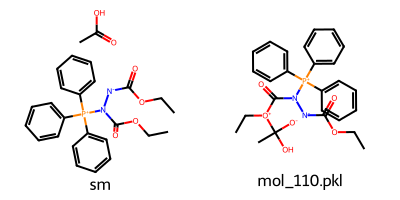

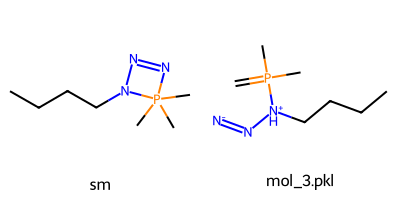

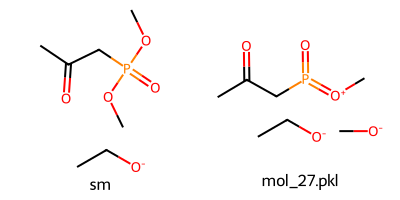

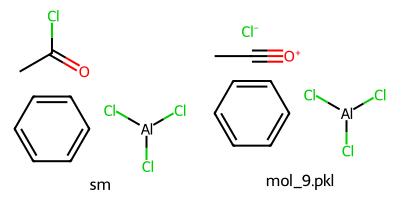

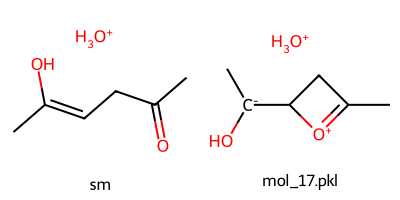

Prepared 5 examples


In [3]:
# === XGBoost exact decision-path explanation (LIST-BASED FEATURES) ===

from platform import node
import xgboost as xgb
import json
import math

# ------------------------------------------------------------------
# 0. Build feature map
# ------------------------------------------------------------------
feature_map = build_feature_map()

# ------------------------------------------------------------------
# 1. Load model
# ------------------------------------------------------------------
booster = xgb.Booster()
booster.load_model("models/v103f2/xg_model.json")

trees = booster.get_dump(dump_format="json", with_stats=True)
trees = [json.loads(t) for t in trees]

# ------------------------------------------------------------------
# 2. Single sample as LIST / ARRAY
# ------------------------------------------------------------------
# Random examples from training_sets/20260202

import os
import pickle
import random

from rdkit.Chem import Draw
from IPython.display import display

from shared.ml_helper import make_fingerprint

training_dir = "training_sets/20260202"
num_examples = 5

# Pick random folders and random valid mechanisms inside them
subdirs = [d for d in os.listdir(training_dir) if os.path.isdir(os.path.join(training_dir, d))]
if not subdirs:
    raise RuntimeError(f"No subdirectories found in {training_dir}")

rng = random.Random()

gemini_examples = []

# String payload for Gemini explanations
gemini_payload = ""

fingerprints_list = []

for _ in range(num_examples):
    while True:
        subdir = rng.choice(subdirs)
        folder_path = os.path.join(training_dir, subdir)
        json_path = os.path.join(folder_path, "data.json")
        sm_path = os.path.join(folder_path, "sm.pkl")
        if not (os.path.exists(json_path) and os.path.exists(sm_path)):
            continue

        with open(json_path, "r") as f:
            data = json.load(f)

        choices = data.get("choices", {})
        valid_choices = [info for info in choices.values() if info.get("probable") is not None and info.get("mechanism") is not None]
        if not valid_choices:
            continue

        info = rng.choice(valid_choices)
        mechanism = info["mechanism"]

        with open(sm_path, "rb") as f:
            sm = pickle.load(f)

        x = make_fingerprint(sm, mechanism)
        fingerprints_list.append(x)
        break

    # Draw starting material and a random product (mol_*.pkl)
    mol_files = [f for f in os.listdir(folder_path) if f.startswith("mol_") and f.endswith(".pkl")]
    product_mol = None
    product_label = None
    if mol_files:
        mol_file = rng.choice(mol_files)
        with open(os.path.join(folder_path, mol_file), "rb") as f:
            product_mol = pickle.load(f)
        product_label = mol_file

    if product_mol is not None:
        img = Draw.MolsToGridImage([sm, product_mol], molsPerRow=2, legends=["sm", product_label])
        display(img)

    gemini_examples.append({
        "folder": folder_path,
        "mechanism": mechanism,
        "fingerprint": x,
        "product": product_label,
    })

print(f"Prepared {len(gemini_examples)} examples")
# ------------------------------------------------------------------
# 3. Tree-walking function (list-based)
# ------------------------------------------------------------------
def walk_tree(node, x, path):
    # Leaf node
    if "leaf" in node:
        return node["leaf"], path

    feature = node["split"]          # e.g. "f17"
    threshold = node["split_condition"]

    # Extract integer index
    idx = int(feature[1:])
    label = feature_map[idx]
    label = idx
    value = x[idx]
  

    if value < threshold:
        next_id = node["yes"]
        # decision = f"{label} ({feature}) = 0 → yes-branch"
        decision = f"{label} ({feature}) = 0"
    else:
        next_id = node["no"]
        # decision = f"{label} ({feature}) = 1 → no-branch"
        decision = f"{label} ({feature}) = 1"
    path.append(decision)

    for child in node["children"]:
        if child["nodeid"] == next_id:
            return walk_tree(child, x, path)

    raise RuntimeError("Child node not found")

# ------------------------------------------------------------------
# 4. Explain prediction
# ------------------------------------------------------------------
import json

config = json.loads(booster.save_config())
base_score = float(
    config["learner"]["learner_model_param"]["base_score"]
)

# learning rate (eta)
def log(*args):
    global gemini_payload
    line = ' '.join(str(a) for a in args)
    gemini_payload += line + '\n'

gb = config["learner"]["gradient_booster"]
tree_params = gb.get("tree_train_param", {})

learning_rate = tree_params.get("learning_rate")
if learning_rate is None:
    learning_rate = tree_params.get("eta")

learning_rate = float(learning_rate)

raw_score = base_score

for i, tree in enumerate(trees):
    leaf_value, path = walk_tree(tree, x, [])

    contribution = learning_rate * leaf_value

    log(f"Tree {i}")
    for step in path:
        log("  •", step)
    log(f"  → Leaf value: {leaf_value:.6f}")
    log(f"  → Contribution (η × leaf): {contribution:.6f}\n")

    raw_score += contribution

probability = 1.0 / (1.0 + math.exp(-raw_score))

log("=" * 60)
log(f"Final raw score (log-odds): {raw_score:.6f}")
log(f"Predicted probability: {probability:.6f}")


In [4]:
import json
import math

output = ""

# ------------------------------------------------------------------
# 1. Extract base_score and learning_rate from booster config
# ------------------------------------------------------------------
config = json.loads(booster.save_config())

base_score = float(
    config["learner"]["learner_model_param"]["base_score"]
)

tree_params = config["learner"]["gradient_booster"]["tree_train_param"]

learning_rate = tree_params.get("learning_rate", tree_params.get("eta"))
learning_rate = float(learning_rate)

# ------------------------------------------------------------------
# 2. Walk trees, collect contributions
# ------------------------------------------------------------------
tree_contributions = []

raw_score = base_score

for idx, x in enumerate(fingerprints_list):
    for i, tree in enumerate(trees):
        leaf_value, path = walk_tree(tree, x, [])

        contribution = learning_rate * leaf_value
        raw_score += contribution

        tree_contributions.append({
            "tree": i,
            "leaf_value": leaf_value,
            "contribution": contribution,
            "abs_contribution": abs(contribution),
            "path": path,
        })

    # ------------------------------------------------------------------
    # 3. Rank trees by absolute contribution
    # ------------------------------------------------------------------
    tree_contributions.sort(
        key=lambda d: d["abs_contribution"],
        reverse=True
    )

    # ------------------------------------------------------------------
    # 4. Pretty print top contributors
    # ------------------------------------------------------------------
    TOP_K = 5

    print("=" * 70)

    print(f"Top {TOP_K} trees by contribution for molecule {idx + 1}")
    output += f"Top {TOP_K} trees by contribution for molecule {idx + 1}\n"

    output += "=" * 70 + "\n"

    for entry in tree_contributions[:TOP_K]:
        print(f"Tree {entry['tree']}")
        output += f"Tree {entry['tree']}\n"
        for step in entry["path"]:
            print("  •", step)
            output += f"  • {step}\n"
        print(f"  → Leaf value: {entry['leaf_value']:.6f}")
        output += f"  → Leaf value: {entry['leaf_value']:.6f}\n"
        print(f"  → Contribution (η × leaf): {entry['contribution']:.6f}")
        output += f"  → Contribution (η × leaf): {entry['contribution']:.6f}\n\n"
        print()

    # ------------------------------------------------------------------
    # 5. Final probability (sanity check)
    # ------------------------------------------------------------------
    probability = 1.0 / (1.0 + math.exp(-raw_score))

    print("=" * 70)
    print(f"Final raw score (log-odds): {raw_score:.6f}")
    output += f"Final raw score (log-odds): {raw_score:.6f}\n"
    print(f"Predicted probability: {probability:.6f}")
    output += f"Predicted probability: {probability:.6f}\n"


Top 5 trees by contribution for molecule 1
Tree 0
  • 84 (f84) = 0
  • 147 (f147) = 1
  • 120 (f120) = 0
  • 82 (f82) = 0
  • 11 (f11) = 0
  • 141 (f141) = 0
  • 159 (f159) = 0
  → Leaf value: -0.645086
  → Contribution (η × leaf): -0.193526

Tree 1
  • 89 (f89) = 0
  • 45 (f45) = 1
  • 67 (f67) = 0
  • 148 (f148) = 1
  → Leaf value: -0.465122
  → Contribution (η × leaf): -0.139537

Tree 2
  • 89 (f89) = 0
  • 45 (f45) = 1
  • 67 (f67) = 0
  • 11 (f11) = 0
  • 111 (f111) = 1
  • 120 (f120) = 0
  • 2 (f2) = 1
  • 43 (f43) = 0
  → Leaf value: -0.411407
  → Contribution (η × leaf): -0.123422

Tree 3
  • 120 (f120) = 0
  • 148 (f148) = 1
  • 11 (f11) = 0
  • 58 (f58) = 1
  • 16 (f16) = 0
  • 15 (f15) = 0
  → Leaf value: -0.382077
  → Contribution (η × leaf): -0.114623

Tree 11
  • 164 (f164) = 1
  • 163 (f163) = 1
  • 160 (f160) = 0
  • 54 (f54) = 0
  • 52 (f52) = 1
  • 149 (f149) = 1
  • 13 (f13) = 1
  • 86 (f86) = 0
  • 35 (f35) = 1
  • 117 (f117) = 0
  → Leaf value: -0.354282
  → Contri

In [5]:
f_map = build_feature_map()

In [6]:
f_map[1]

'mechanism_type=1'

In [7]:
def extract_rules(node, path_conditions):
    rules = []

    # Leaf
    if "leaf" in node:
        rules.append({
            "conditions": tuple(sorted(path_conditions)),
            "leaf": node["leaf"],
            "cover": node.get("cover", 0)
        })
        return rules

    feature = node["split"]
    threshold = node["split_condition"]
    idx = int(feature[1:])

    # YES branch (< threshold)
    yes_condition = f"{idx}=0"
    for child in node["children"]:
        if child["nodeid"] == node["yes"]:
            rules += extract_rules(
                child,
                path_conditions + [yes_condition]
            )

    # NO branch (>= threshold)
    no_condition = f"{idx}=1"
    for child in node["children"]:
        if child["nodeid"] == node["no"]:
            rules += extract_rules(
                child,
                path_conditions + [no_condition]
            )

    return rules

In [8]:
all_rules = []

for tree in trees:
    rules = extract_rules(tree, [])
    all_rules.extend(rules)

In [9]:
print(all_rules[:5])

[{'conditions': ('117=0', '121=0', '147=0', '155=0', '163=0', '24=0', '52=0', '78=0', '81=0', '84=0'), 'leaf': 0.371012896, 'cover': 10.1818743}, {'conditions': ('117=0', '121=0', '147=0', '155=0', '163=0', '24=0', '52=1', '78=0', '81=0', '84=0'), 'leaf': 0.0338043123, 'cover': 10.430213}, {'conditions': ('117=0', '121=0', '147=0', '155=1', '163=0', '24=0', '78=0', '81=0', '84=0'), 'leaf': -0.465721846, 'cover': 2.48338413}, {'conditions': ('117=0', '121=0', '147=0', '163=0', '24=0', '78=1', '81=0', '84=0'), 'leaf': -0.52190721, 'cover': 3.97341442}, {'conditions': ('117=0', '121=0', '147=0', '163=0', '24=1', '81=0', '84=0'), 'leaf': -0.52190721, 'cover': 3.97341442}]


In [10]:
from collections import defaultdict
import statistics

rule_stats = defaultdict(lambda: {"leafs": [], "cover": 0})

for r in all_rules:
    key = r["conditions"]

    rule_stats[key]["leafs"].append(r["leaf"])
    rule_stats[key]["cover"] += r["cover"]

In [11]:
heuristics = []

for cond, stats in rule_stats.items():

    mean_leaf = statistics.mean(stats["leafs"])
    trees_supporting = len(stats["leafs"])
    cover = stats["cover"]

    strength = abs(mean_leaf) * trees_supporting

    heuristics.append({
        "conditions": cond,
        "mean_leaf": mean_leaf,
        "trees": trees_supporting,
        "cover": cover,
        "strength": strength
    })

In [12]:
heuristics.sort(key=lambda x: x["strength"], reverse=True)

In [13]:
for h in heuristics[:30]:

    cond_str = " AND ".join(h["conditions"])

    print("RULE")
    print(" IF", cond_str)
    print(f" THEN mean leaf = {h['mean_leaf']:.3f}")
    print(f" trees = {h['trees']}")
    print(f" cover = {h['cover']}")
    print(f" strength = {h['strength']:.3f}")
    print()

RULE
 IF 11=0 AND 120=0 AND 13=1 AND 148=1 AND 19=0 AND 58=0
 THEN mean leaf = -0.325
 trees = 4
 cover = 28.16050892
 strength = 1.298

RULE
 IF 114=1 AND 45=1 AND 67=1 AND 89=0
 THEN mean leaf = 0.307
 trees = 4
 cover = 17.94915509
 strength = 1.226

RULE
 IF 120=0 AND 130=1 AND 148=0 AND 149=0 AND 29=0 AND 78=0
 THEN mean leaf = -0.348
 trees = 3
 cover = 181.73166050000003
 strength = 1.045

RULE
 IF 11=0 AND 120=0 AND 148=1 AND 150=0 AND 155=0 AND 15=0 AND 16=0 AND 58=1
 THEN mean leaf = -0.332
 trees = 3
 cover = 266.6871037
 strength = 0.996

RULE
 IF 11=1 AND 120=0 AND 148=1 AND 45=1 AND 75=0 AND 77=0
 THEN mean leaf = -0.328
 trees = 3
 cover = 8.976527690000001
 strength = 0.984

RULE
 IF 11=0 AND 120=0 AND 130=1 AND 148=0 AND 149=0 AND 78=1
 THEN mean leaf = -0.308
 trees = 3
 cover = 20.491781210000003
 strength = 0.924

RULE
 IF 11=0 AND 120=0 AND 148=1 AND 150=0 AND 155=1 AND 15=0 AND 16=0 AND 22=0 AND 58=1
 THEN mean leaf = -0.303
 trees = 3
 cover = 53.6977272
 strengt

In [14]:
from collections import defaultdict

bit_scores = defaultdict(float)
bit_counts = defaultdict(int)

for h in heuristics:

    score = h["mean_leaf"] * h["trees"]

    for cond in h["conditions"]:

        bit, val = cond.split("=")
        bit = int(bit)
        val = int(val)

        # treat presence and absence separately
        key = (bit, val)

        bit_scores[key] += score
        bit_counts[key] += 1

In [15]:
motifs = []

for (bit, val), score in bit_scores.items():

    motifs.append({
        "bit": bit,
        "value": val,
        "score": score,
        "count": bit_counts[(bit,val)]
    })

motifs.sort(key=lambda x: abs(x["score"]), reverse=True)

In [16]:
motifs

[{'bit': 11, 'value': 0, 'score': -90.41141870656531, 'count': 1741},
 {'bit': 120, 'value': 0, 'score': -71.6806586995742, 'count': 1527},
 {'bit': 48, 'value': 0, 'score': -41.42005576158207, 'count': 1562},
 {'bit': 160, 'value': 0, 'score': -39.92221296097603, 'count': 853},
 {'bit': 13, 'value': 1, 'score': -35.136581492063975, 'count': 1051},
 {'bit': 23, 'value': 0, 'score': -34.74898105401497, 'count': 752},
 {'bit': 164, 'value': 1, 'score': -29.09515571849332, 'count': 1560},
 {'bit': 89, 'value': 0, 'score': -27.161136812670026, 'count': 478},
 {'bit': 141, 'value': 0, 'score': -25.15241078331739, 'count': 688},
 {'bit': 57, 'value': 0, 'score': -24.68746964950461, 'count': 980},
 {'bit': 58, 'value': 1, 'score': -24.51480719144599, 'count': 397},
 {'bit': 148, 'value': 1, 'score': -24.227211378054008, 'count': 567},
 {'bit': 45, 'value': 0, 'score': -23.837188804180066, 'count': 748},
 {'bit': 163, 'value': 0, 'score': -22.774666438005504, 'count': 416},
 {'bit': 147, 'valu

In [17]:
from itertools import combinations

pair_scores = defaultdict(float)

for h in heuristics:

    score = h["mean_leaf"] * h["trees"]

    for a,b in combinations(h["conditions"],2):

        key = tuple(sorted([a,b]))
        pair_scores[key] += score

In [18]:
pair_scores

defaultdict(float,
            {('11=0', '120=0'): -36.33623748426824,
             ('11=0', '13=1'): -20.163284141299012,
             ('11=0', '148=1'): -14.472650983189,
             ('11=0', '19=0'): -6.6364078994729985,
             ('11=0', '58=0'): -3.907159416920003,
             ('120=0', '13=1'): -11.021436451149002,
             ('120=0', '148=1'): -18.806674074578996,
             ('120=0', '19=0'): -1.436486189,
             ('120=0', '58=0'): -0.6567638520199991,
             ('13=1', '148=1'): -4.443800902438999,
             ('13=1', '19=0'): -4.7596107542990005,
             ('13=1', '58=0'): -1.7207615086699997,
             ('148=1', '19=0'): -1.2383101479999998,
             ('148=1', '58=0'): -0.8961409725699993,
             ('19=0', '58=0'): -1.6316937333999997,
             ('114=1', '45=1'): 0.5271417283600004,
             ('114=1', '67=1'): 2.342839001,
             ('114=1', '89=0'): 0.8590127788700003,
             ('45=1', '67=1'): 1.2704317495000002,
    

In [19]:
f_map[1]

'mechanism_type=1'

In [20]:
positive = sorted(
    [(k,v) for k,v in pair_scores.items() if v > 0],
    key=lambda x: x[1],
    reverse=True
)

negative = sorted(
    [(k,v) for k,v in pair_scores.items() if v < 0],
    key=lambda x: x[1]
)

In [21]:
print("Top positive motifs")
for (a,b), score in positive[:20]:
    print(f"{f_map[int(a.split('=')[0])]}={a.split('=')[1]} AND {f_map[int(b.split('=')[0])]}={b.split('=')[1]} → {score:.3f}")

print("\nTop negative motifs")
for (a,b), score in negative[:20]:
    print(f"{f_map[int(a.split('=')[0])]}={a.split('=')[1]} AND {f_map[int(b.split('=')[0])]}={b.split('=')[1]} → {score:.3f}")

Top positive motifs
atom2.charge=pos=1 AND atom2.element=alkali=0 → 9.407
ring=4=1 AND atom2.charge=pos=1 → 8.124
atom1.charge=neg=1 AND atom4.charge=pos=1 → 7.176
atom1.charge=neg=1 AND atom1.H=0=0 → 7.023
atom1.charge=neg=1 AND atom2.charge=pos=1 → 6.799
atom2.charge=pos=1 AND mechanism_type=4=0 → 6.218
atom2.element=alkali=0 AND atom3.hybrid=sp=1 → 6.124
ring=4=1 AND atom2.element=alkali=0 → 5.905
atom4.charge=pos=1 AND atom2.element=alkali=0 → 5.512
atom2.charge=pos=1 AND atom3.hybrid=sp=1 → 5.427
atom1.adj=C-EN=1 AND atom2.charge=pos=1 → 5.409
mechanism_type=1=1 AND atom2.charge=pos=1 → 5.354
atom1.charge=neg=1 AND atom2.hybrid=sp2=0 → 4.998
atom1.element=O=1 AND atom2.charge=pos=1 → 4.846
atom1.charge=neg=1 AND atom2.adj=C=EN=1 → 4.806
atom1.H=0=1 AND atom1.element=N=1 → 4.761
atom1.element=N=1 AND atom3.hybrid=sp=1 → 4.704
ring=4=1 AND mechanism_type=1=1 → 4.581
ring=4=1 AND atom3.hybrid=sp=1 → 4.577
atom1.charge=neg=1 AND atom1.adj=CH=1 → 4.527

Top negative motifs
atom1.charge

## Conditional probability impact analysis

Ignore the older exploratory uplift/downgrade variants that used to be here. The cells you want to run are the next three:

1. Classify the bitvector columns into `zero_one_cols`, `nan_one_cols`, and `other_cols`.
2. Define the final `conditional_probabilities(...)` helper that returns signed `impact` values.
3. Load the model, set `base_cond`, and build `df`.


In [42]:
import pandas as pd

In [46]:
# Step 1: run this cell first to classify the feature columns.
X = pd.read_csv("bitvectors.csv", header=None)
zero_one_cols = []
nan_one_cols = []
other_cols = []

for col in X.columns:
    col_vals = X[col]
    non_nan = col_vals.dropna().unique()
    unique_non_nan = set(non_nan)

    if col_vals.isna().sum() == 0 and unique_non_nan == {0, 1}:
        zero_one_cols.append(col)
    elif col_vals.isna().sum() > 0 and unique_non_nan == {1}:
        nan_one_cols.append(col)
    else:
        other_cols.append(col)

print("0/1 columns:", zero_one_cols)
print("nan/1 columns:", nan_one_cols)
print("other columns:", other_cols)

0/1 columns: [47, 48, 49, 50, 51, 52, 53, 54, 55, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 71, 72, 73, 75, 76, 77, 78, 79, 81, 82]
nan/1 columns: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 163, 164, 165, 166, 167]
other columns: [11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 56, 70, 74, 80, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156, 157, 158, 159, 160, 161, 162]


In [44]:
# Step 2: run this cell next to define the final impact helper.
import numpy as np
import pandas as pd

def conditional_probabilities(model, X, base_cond, baseline, columns_to_skip=[]):
    results = []
    columns_to_skip = {str(col) for col in columns_to_skip}

    for col in X.columns:
        col_num = int(col)

        if col in columns_to_skip:
            continue

        if col_num in nan_one_cols:
            conditions_to_check = [(1, X[col] == 1), ("nan", np.isnan(X[col]))]
        else:
            values_to_check = [0, 1] if col_num in zero_one_cols or col_num in other_cols else [1]
            conditions_to_check = [(val, X[col] == val) for val in values_to_check]

        for val, value_cond in conditions_to_check:
            cond = base_cond & value_cond
            subset = X[cond]

            if len(subset) == 0:
                continue

            preds = model.predict(subset)
            prob = np.mean(preds == 1)
            impact = prob - baseline

            results.append({
                "feature_num": col_num,
                "feature": f_map[col_num],
                "value": val,
                "samples": len(subset),
                "prob_positive": prob,
                "impact": impact,
                "abs_impact": abs(impact),
                "direction": "positive" if impact > 0 else "negative" if impact < 0 else "neutral"
            })

    if not results:
        return pd.DataFrame(columns=["feature_num", "feature", "value", "samples", "prob_positive", "impact", "abs_impact", "direction"])

    return pd.DataFrame(results).sort_values(["abs_impact", "impact"], ascending=[False, False])

In [45]:
# Step 3: run this cell to compute the ranked positive/negative impacts.
clf = xgb.XGBClassifier()
clf.load_model("models/v104w20/xg_model.json")

X = pd.read_csv("bitvectors_df.csv")
impacts = {}

base_cond = ~(np.isnan(X["1"])) & (X["160"] ==1)
base_preds = clf.predict(X[base_cond])

baseline = np.mean(base_preds == 1)
print(baseline)
df = conditional_probabilities(clf, X, base_cond, baseline, columns_to_skip=["1", "160"])

nan


/home/rd611/.conda/envs/aim/lib/python3.13/site-packages/numpy/_core/fromnumeric.py:3824: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/rd611/.conda/envs/aim/lib/python3.13/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


KeyError: 'abs_impact'

In [33]:
df.head(20)

,feature_num,feature,value,samples,prob_positive,impact,abs_impact,direction
14,30,atom1.element=S,1,2,1.000000,0.756491,0.756491,positive
9,22,atom1.element=C,1,13,0.846154,0.602644,0.602644,positive
13,29,atom1.element=P,1,19,0.842105,0.598596,0.598596,positive
4,16,atom1.H>2,1,11,0.818182,0.574672,0.574672,positive
19,36,atom1.aromatic=yes,1,6,0.666667,0.423157,0.423157,positive
5,17,atom1.hybrid=sp,1,8,0.625000,0.381491,0.381491,positive
10,23,atom1.element=N,1,144,0.500000,0.256491,0.256491,positive
12,25,atom1.element=F,1,14,0.000000,-0.243509,0.243509,negative
17,33,atom1.element=I,1,10,0.000000,-0.243509,0.243509,negative
20,37,atom1.adj=C+,1,4,0.000000,-0.243509,0.243509,negative


In [33]:
clf = xgb.XGBClassifier()
clf.load_model("models/v103f2/xg_model.json")
X = pd.read_csv("bitvectors_df.csv")
base_cond = ~(np.isnan(X["1"])) & (X["159"] == 1 & (X["58"] == 1))
base_preds = clf.predict(X[base_cond])
print(base_preds)
print(sum(base_preds))

[0 0 0 ... 0 0 0]
178


In [34]:
X[base_cond].iloc[0]

0      NaN
1      1.0
2      NaN
3      NaN
4      NaN
      ... 
163    NaN
164    NaN
165    NaN
166    NaN
167    NaN
Name: 97, Length: 168, dtype: float64

In [41]:
f_map[160]

'bond2=double'

In [34]:
print(X[11])

KeyError: 11

In [ ]:
f_map[159]

'bond2=single'

In [ ]:
159 in other_cols

True